# 🗺️ Notebook 02 · Análisis Espacial
---
**Proyecto:** Bogotá — Análisis Predictivo del Mercado Inmobiliario Urbano  
**Fuente:** UAECD / IDECA · 2020–2026  
**Autor:** Kevin Palacio Martinez

---
## 🎯 Objetivo

Explorar la distribución geográfica del valor comercial por m² en Bogotá,
identificar patrones de concentración espacial y detectar zonas de alta
y baja valorización mediante técnicas de autocorrelación espacial.

## 📋 Contenido

| Sección | Descripción |
|---|---|
| 1 | Carga de datos geoespaciales desde PostGIS |
| 2 | Mapas de calor interactivos por año con Folium |
| 3 | Autocorrelación espacial — Índice de Moran's I |
| 4 | Clusters espaciales LISA — zonas HH, LL, HL, LH |
| 5 | Delimitación urbano / periurbano / rural |
| 6 | Exportación de resultados para QGIS |


### ⚠️Nota importante: los mapas interactivos html al contar con gran cantidad de poligonos pueden ser pesados para lograr la visualizacion en algunos navegadores. Se recomienda primero establecer las configuraciones de lo que se desea observar y despues acercar a la zona deseada. 


---
## ⚙️ Sección 1 · Carga de datos geoespaciales

> A diferencia del notebook 01, aquí cargamos el dataset **con geometría**
> directamente desde PostGIS usando GeoPandas.  
> Se usa el dataset limpio con imputación ya aplicada (`valor_final`).

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import seaborn as sns
import folium
from folium.plugins import HeatMap
from sqlalchemy import create_engine
from db_config import DB_URL

# Configuración visual
pd.set_option('display.float_format', '{:,.0f}'.format)
sns.set_theme(style="whitegrid", font_scale=1.1)

engine = create_engine(DB_URL)
print("✓ Conexión establecida")

✓ Conexión establecida


In [6]:
# Carga con geometría desde PostGIS
query_geo = """
    SELECT
        id, anio, cod_manzana,
        localidad, cod_localidad,
        sector, tipo_territorio,
        valor_mediano, valor_final,
        geom
    FROM catastro.valor_manzana
    WHERE valor_final > 0
    ORDER BY anio, localidad;
"""

gdf = gpd.read_postgis(query_geo, engine, geom_col='geom')
gdf = gdf.set_crs(4326, allow_override=True)

print(f"✓ Registros cargados  : {len(gdf):,}")
print(f"✓ CRS                 : {gdf.crs}")
print(f"✓ Años disponibles    : {sorted(gdf['anio'].unique())}")
print(f"✓ Tipos de geometría  : {gdf.geom_type.unique()}")
print(f"\n── Primeras filas ───────────────────────────────────────")
display(gdf.drop(columns='geom').head())

✓ Registros cargados  : 298,010
✓ CRS                 : EPSG:4326
✓ Años disponibles    : [2020, 2021, 2022, 2023, 2024, 2025, 2026]
✓ Tipos de geometría  : ['MultiPolygon']

── Primeras filas ───────────────────────────────────────


,id,anio,cod_manzana,localidad,cod_localidad,sector,tipo_territorio,valor_mediano,valor_final
0,36308,2020,001202002,ANTONIO NARIÑO,15,CIUDAD BERNA,urbano,"1,900,000","1,900,000"
1,32336,2020,001204020,ANTONIO NARIÑO,15,CIUDAD JARDIN SUR,urbano,"1,900,000","1,900,000"
2,34062,2020,002102004,ANTONIO NARIÑO,15,SAN ANTONIO,urbano,"2,350,000","2,350,000"
3,32110,2020,001204001,ANTONIO NARIÑO,15,CIUDAD JARDIN SUR,urbano,"1,900,000","1,900,000"
4,25560,2020,001204007,ANTONIO NARIÑO,15,CIUDAD JARDIN SUR,urbano,"1,900,000","1,900,000"


---
## 🌡️ Sección 2 · Mapas de calor interactivos con Folium

> Se generan mapas interactivos del valor por m² para los años
> **2020, 2023 y 2026**, permitiendo comparar visualmente la evolución
> espacial de la valorización en el territorio.
>
> Los mapas se exportan como archivos `.html` navegables
> en `reports/figures/`.

In [13]:
def crear_mapa_valor(gdf_anio, anio, output_path):
    """Mapa interactivo con leyenda, escala, título y control de capas."""
    import branca.colormap as cm

    gdf_c = gdf_anio.copy()
    gdf_c['lat'] = gdf_c['geom'].to_crs(3116).centroid.to_crs(4326).y
    gdf_c['lon'] = gdf_c['geom'].to_crs(3116).centroid.to_crs(4326).x

    max_val = gdf_c['valor_final'].quantile(0.95)
    gdf_c['peso'] = (gdf_c['valor_final'].clip(upper=max_val) / max_val)

    # Mapa base
    m = folium.Map(
        location=[4.711, -74.0721],
        zoom_start=11,
        tiles=None
    )

    # Capas base seleccionables
    folium.TileLayer('CartoDB positron',    name='Claro',    control=True).add_to(m)
    folium.TileLayer('CartoDB dark_matter', name='Oscuro',   control=True).add_to(m)
    folium.TileLayer('OpenStreetMap',       name='Calles',   control=True).add_to(m)

    # Capa de calor
    heat_data = gdf_c[['lat', 'lon', 'peso']].dropna().values.tolist()
    heat_layer = folium.FeatureGroup(name=f'Calor valor m² ({anio})', show=True)
    HeatMap(
        heat_data,
        min_opacity=0.3,
        max_zoom=13,
        radius=12,
        blur=10,
        gradient={'0.2': '#313695', '0.4': '#4575b4',
                  '0.6': '#f46d43', '0.8': '#d73027', '1.0': '#a50026'}
    ).add_to(heat_layer)
    heat_layer.add_to(m)

    # Control de capas
    folium.LayerControl(position='topright', collapsed=False).add_to(m)

    # Escala
    folium.plugins.MeasureControl(position='bottomleft').add_to(m)

    # Colormap como leyenda
    colormap = cm.LinearColormap(
        colors=['#313695', '#4575b4', '#f46d43', '#d73027', '#a50026'],
        vmin=0,
        vmax=int(max_val),
        caption=f'Valor comercial por m² — COP ({anio})'
    )
    colormap.add_to(m)

    # Título flotante
    titulo_html = f'''
        <div style="position: fixed; top: 15px; left: 55px; z-index: 1000;
                    background-color: white; padding: 10px 15px;
                    border-radius: 8px; border: 1px solid #ccc;
                    font-family: Arial, sans-serif; font-size: 14px;
                    font-weight: bold; color: #1e3a5f; box-shadow: 2px 2px 6px rgba(0,0,0,0.2);">
            🏙️ Bogotá — Valor comercial por m² · {anio}<br>
            <span style="font-size:11px; font-weight:normal; color:#555;">
                Fuente: UAECD / IDECA · Elaboración propia
            </span>
        </div>
    '''
    m.get_root().html.add_child(folium.Element(titulo_html))

    m.save(output_path)
    print(f"  ✓ Mapa {anio} guardado → {output_path}")
    return m

# Generar mapas para todos los años
años_mapa = [2020, 2021, 2022, 2023, 2024, 2025, 2026]
for anio in años_mapa:
    gdf_anio = gdf[gdf['anio'] == anio]
    crear_mapa_valor(
        gdf_anio, anio,
        f'../reports/figures/mapa_calor_{anio}.html'
    )

print("\n✓ Mapas interactivos generados para todos los años")

  ✓ Mapa 2020 guardado → ../reports/figures/mapa_calor_2020.html
  ✓ Mapa 2021 guardado → ../reports/figures/mapa_calor_2021.html
  ✓ Mapa 2022 guardado → ../reports/figures/mapa_calor_2022.html
  ✓ Mapa 2023 guardado → ../reports/figures/mapa_calor_2023.html
  ✓ Mapa 2024 guardado → ../reports/figures/mapa_calor_2024.html
  ✓ Mapa 2025 guardado → ../reports/figures/mapa_calor_2025.html
  ✓ Mapa 2026 guardado → ../reports/figures/mapa_calor_2026.html

✓ Mapas interactivos generados para todos los años


---
## 📐 Sección 3 · Autocorrelación espacial — Índice de Moran's I

> El **Índice de Moran's I** mide si los valores similares tienden
> a agruparse espacialmente (autocorrelación positiva) o si se
> distribuyen aleatoriamente.
>
> - **I cercano a +1** → zonas de alto valor rodeadas de alto valor
> - **I cercano a 0** → distribución aleatoria
> - **I cercano a -1** → zonas de alto valor rodeadas de bajo valor
>
> Se calcula para cada año para ver si la concentración espacial
> aumenta o disminuye en el tiempo.

> ⚠️ **Nota técnica:** El cálculo usa centroides de manzana y una
> matriz de pesos espaciales por contigüidad (Queen).  
> Se trabaja con una muestra representativa por año para eficiencia computacional.

Calculando Moran's I para 2020... I=0.6876 · p=0.0010
Calculando Moran's I para 2021... I=0.7443 · p=0.0010
Calculando Moran's I para 2022... I=0.7034 · p=0.0010
Calculando Moran's I para 2023... I=0.7172 · p=0.0010
Calculando Moran's I para 2024... I=0.7389 · p=0.0010
Calculando Moran's I para 2025... I=0.6771 · p=0.0010
Calculando Moran's I para 2026... I=0.7045 · p=0.0010

── Resultados Índice de Moran's I ──────────────────────


,anio,moran_i,p_value,z_score,significativo
0,2020,1,0,106,Sí
1,2021,1,0,118,Sí
2,2022,1,0,105,Sí
3,2023,1,0,108,Sí
4,2024,1,0,111,Sí
5,2025,1,0,103,Sí
6,2026,1,0,108,Sí


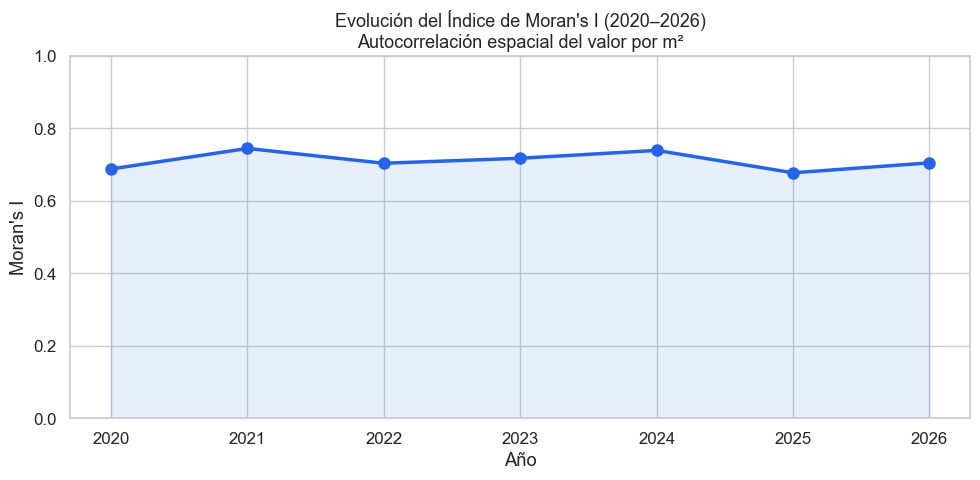

✓ Gráfico guardado en reports/figures/


In [9]:
from libpysal.weights import Queen
from esda.moran import Moran
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# pip install libpysal esda

resultados_moran = []

for anio in sorted(gdf['anio'].unique()):
    print(f"Calculando Moran's I para {anio}...", end=' ')
    
    gdf_anio = gdf[gdf['anio'] == anio].copy()
    
    # Muestra representativa para eficiencia (máx 8.000 manzanas)
    if len(gdf_anio) > 8000:
        gdf_anio = gdf_anio.sample(8000, random_state=42)
    
    # Usar centroides para la matriz de pesos
    gdf_c = gdf_anio.copy()
    gdf_c['geom'] = gdf_c['geom'].centroid
    
    try:
        w = Queen.from_dataframe(gdf_c, geom_col='geom', silence_warnings=True)
        w.transform = 'r'
        
        moran = Moran(gdf_c['valor_final'].values, w)
        
        resultados_moran.append({
            'anio':      anio,
            'moran_i':   round(moran.I, 4),
            'p_value':   round(moran.p_sim, 4),
            'z_score':   round(moran.z_sim, 2),
            'significativo': 'Sí' if moran.p_sim < 0.05 else 'No'
        })
        print(f"I={moran.I:.4f} · p={moran.p_sim:.4f}")
    
    except Exception as e:
        print(f"Error: {e}")

df_moran = pd.DataFrame(resultados_moran)
print("\n── Resultados Índice de Moran's I ──────────────────────")
display(df_moran)

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_moran['anio'], df_moran['moran_i'],
        marker='o', linewidth=2.5, color='#2563EB', markersize=8)
ax.fill_between(df_moran['anio'], df_moran['moran_i'],
                alpha=0.1, color='#2563EB')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_title("Evolución del Índice de Moran's I (2020–2026)\nAutocorrelación espacial del valor por m²",
             fontsize=13)
ax.set_xlabel('Año')
ax.set_ylabel("Moran's I")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../reports/figures/05_morans_i_evolucion.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfico guardado en reports/figures/")

---
## 🔴 Sección 4 · Clusters espaciales LISA

> El análisis **LISA (Local Indicators of Spatial Association)**
> clasifica cada manzana en una de cuatro categorías:
>
> | Categoría | Significado |
> |---|---|
> | 🔴 **HH** (High-High) | Alto valor rodeado de alto valor — núcleos premium |
> | 🔵 **LL** (Low-Low) | Bajo valor rodeado de bajo valor — zonas rezagadas |
> | 🟠 **HL** (High-Low) | Alto valor rodeado de bajo valor — outliers positivos |
> | 🟡 **LH** (Low-High) | Bajo valor rodeado de alto valor — zonas en transición |
>
> Se calcula para **2020 y 2026** para comparar la evolución
> de los clusters en el período analizado.

> ⚠️Nota:

>NS (Not Significant) — la manzana tiene un cluster calculado pero su p-value es ≥ 0.05, es decir estadísticamente no es confiable para afirmar que pertenece a un cluster real. Se conserva en el mapa pero se etiqueta aparte.

>Sin calcular — manzanas del dataset 2026 que no entraron en la muestra de 6.000 usada para el cálculo LISA (por eficiencia computacional). No es un error, es una limitación del muestreo.

Calculando LISA 2020... ✓
Calculando LISA 2026... ✓


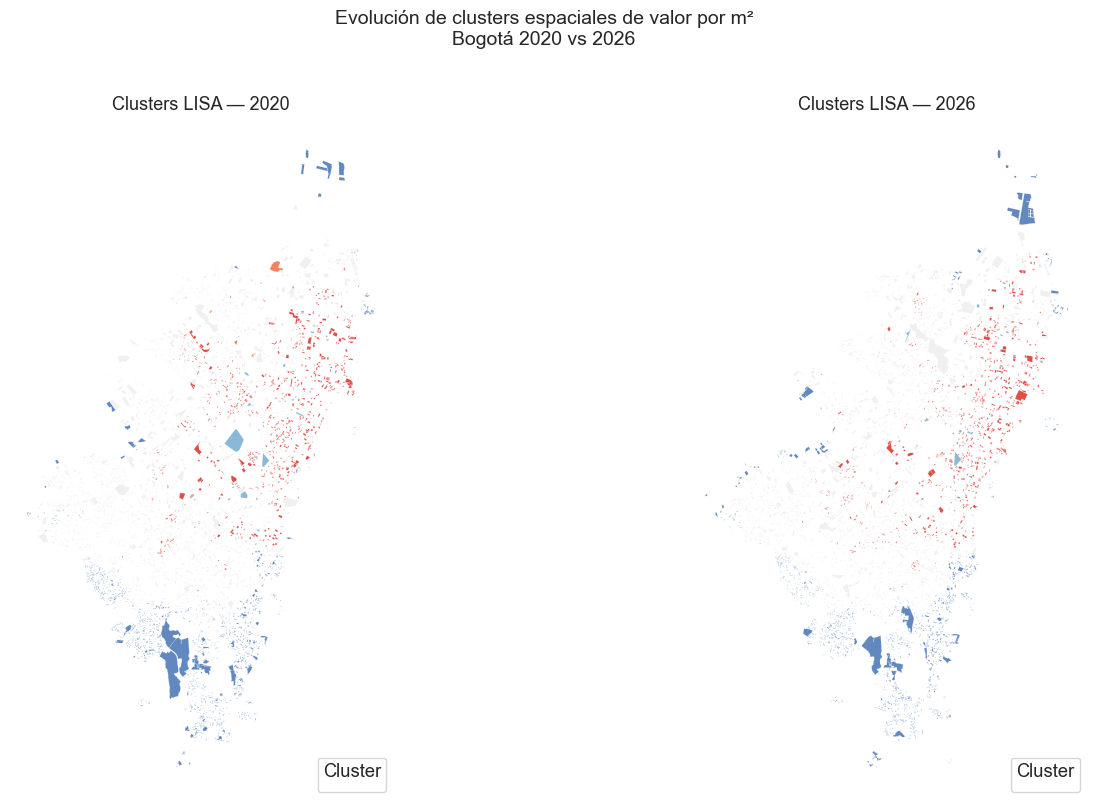


── Distribución de clusters LISA ────────────────────────

▸ 2020


,lisa_cluster,manzanas,valor_mediano
4,NS,3481,"1,900,000"
3,LL,1529,"620,000"
0,HH,827,"2,900,000"
2,LH,93,"900,000"
1,HL,9,"2,200,000"



▸ 2026


,lisa_cluster,manzanas,valor_mediano
4,NS,3635,"2,900,000"
3,LL,1443,"940,000"
0,HH,850,"4,380,000"
2,LH,63,"1,200,000"
1,HL,9,"2,940,000"


✓ Gráfico guardado en reports/figures/


In [10]:
from esda.moran import Moran_Local

def calcular_lisa(gdf_anio, anio, n_muestra=6000):
    """Calcula clusters LISA para un año dado."""
    
    gdf_c = gdf_anio.copy()
    if len(gdf_c) > n_muestra:
        gdf_c = gdf_c.sample(n_muestra, random_state=42)
    
    gdf_c['geom_centroide'] = gdf_c['geom'].centroid
    gdf_temp = gdf_c.set_geometry('geom_centroide')
    
    w = Queen.from_dataframe(gdf_temp, silence_warnings=True)
    w.transform = 'r'
    
    lisa = Moran_Local(gdf_c['valor_final'].values, w)
    
    # Clasificar clusters (solo significativos p<0.05)
    labels = {1: 'HH', 2: 'LH', 3: 'LL', 4: 'HL'}
    gdf_c['lisa_cluster'] = [
        labels.get(q, 'NS') if p < 0.05 else 'NS'
        for q, p in zip(lisa.q, lisa.p_sim)
    ]
    gdf_c['lisa_anio'] = anio
    return gdf_c[['cod_manzana', 'localidad', 'valor_final',
                   'geom', 'lisa_cluster', 'lisa_anio']]

print("Calculando LISA 2020...", end=' ')
lisa_2020 = calcular_lisa(gdf[gdf['anio'] == 2020], 2020)
print("✓")

print("Calculando LISA 2026...", end=' ')
lisa_2026 = calcular_lisa(gdf[gdf['anio'] == 2026], 2026)
print("✓")

# Visualización comparativa
colores_lisa = {
    'HH': '#d73027', 'LL': '#4575b4',
    'HL': '#f46d43', 'LH': '#74add1', 'NS': '#eeeeee'
}

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, (lisa_df, anio) in zip(axes, [(lisa_2020, 2020), (lisa_2026, 2026)]):
    gdf_plot = gpd.GeoDataFrame(lisa_df, geometry='geom', crs=4326)
    
    for cluster, color in colores_lisa.items():
        subset = gdf_plot[gdf_plot['lisa_cluster'] == cluster]
        if len(subset) > 0:
            subset.plot(ax=ax, color=color, linewidth=0.1,
                       label=cluster, alpha=0.85)
    
    ax.set_title(f'Clusters LISA — {anio}', fontsize=13)
    ax.set_axis_off()
    ax.legend(title='Cluster', loc='lower right', fontsize=9)

plt.suptitle('Evolución de clusters espaciales de valor por m²\nBogotá 2020 vs 2026',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/06_lisa_clusters_2020_2026.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Resumen por cluster
print("\n── Distribución de clusters LISA ────────────────────────")
for anio, lisa_df in [(2020, lisa_2020), (2026, lisa_2026)]:
    print(f"\n▸ {anio}")
    display(
        lisa_df.groupby('lisa_cluster').agg(
            manzanas=('cod_manzana', 'count'),
            valor_mediano=('valor_final', 'median')
        ).reset_index().sort_values('manzanas', ascending=False)
    )
print("✓ Gráfico guardado en reports/figures/")

---
## 🌿 Sección 5 · Delimitación urbano / periurbano / rural

> Visualización geográfica de la clasificación territorial aplicada
> en el notebook 01.  
> Esta delimitación es la base para el modelo de expansión urbana
> del notebook 05.

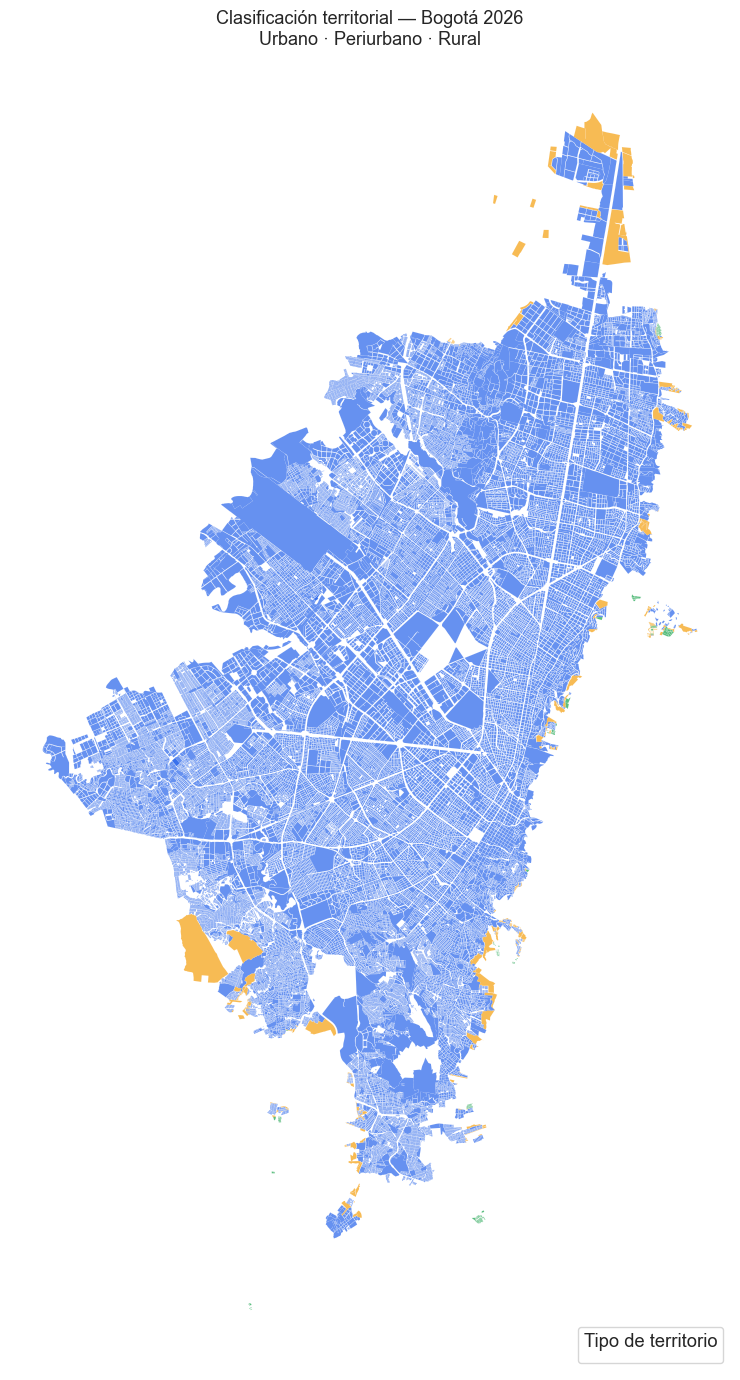

✓ Mapa territorial guardado → reports/figures/mapa_territorial_2026.html


In [14]:
# Mapa estático
gdf_2026 = gdf[gdf['anio'] == 2026].copy()

colores_territorio = {
    'urbano':    '#2563EB',
    'periurbano':'#F59E0B',
    'rural':     '#16A34A'
}

fig, ax = plt.subplots(figsize=(12, 14))
for tipo, color in colores_territorio.items():
    subset = gdf_2026[gdf_2026['tipo_territorio'] == tipo]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, linewidth=0.05,
                   alpha=0.7, label=f'{tipo.capitalize()} ({len(subset):,})')

ax.set_title('Clasificación territorial — Bogotá 2026\nUrbano · Periurbano · Rural', fontsize=13)
ax.set_axis_off()
ax.legend(title='Tipo de territorio', loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/figures/07_clasificacion_territorial_2026.png', dpi=150, bbox_inches='tight')
plt.show()

# Mapa HTML interactivo
m_terr = folium.Map(location=[4.711, -74.0721], zoom_start=11, tiles=None)

folium.TileLayer('CartoDB positron',    name='Claro',  control=True).add_to(m_terr)
folium.TileLayer('CartoDB dark_matter', name='Oscuro', control=True).add_to(m_terr)
folium.TileLayer('OpenStreetMap',       name='Calles', control=True).add_to(m_terr)

colores_hex = {
    'urbano':    '#2563EB',
    'periurbano':'#F59E0B',
    'rural':     '#16A34A'
}

for tipo, color in colores_hex.items():
    subset = gdf_2026[gdf_2026['tipo_territorio'] == tipo].copy()
    if len(subset) == 0:
        continue

    capa = folium.FeatureGroup(name=f'{tipo.capitalize()} ({len(subset):,})', show=True)
    folium.GeoJson(
        subset[['geom', 'tipo_territorio', 'localidad', 'valor_final']].rename(
            columns={'geom': 'geometry'}
        ).set_geometry('geometry'),
        style_function=lambda f, c=color: {
            'fillColor': c,
            'color':     c,
            'weight':    0.3,
            'fillOpacity': 0.6
        },
        tooltip=folium.GeoJsonTooltip(
            fields=['tipo_territorio', 'localidad', 'valor_final'],
            aliases=['Territorio', 'Localidad', 'Valor m² (COP)'],
            localize=True
        )
    ).add_to(capa)
    capa.add_to(m_terr)

folium.LayerControl(position='topright', collapsed=False).add_to(m_terr)
folium.plugins.MeasureControl(position='bottomleft').add_to(m_terr)

titulo_terr = '''
    <div style="position: fixed; top: 15px; left: 55px; z-index: 1000;
                background-color: white; padding: 10px 15px;
                border-radius: 8px; border: 1px solid #ccc;
                font-family: Arial, sans-serif; font-size: 14px;
                font-weight: bold; color: #1e3a5f; box-shadow: 2px 2px 6px rgba(0,0,0,0.2);">
        🌍 Bogotá — Clasificación territorial · 2026<br>
        <span style="font-size:11px; font-weight:normal; color:#555;">
            Fuente: UAECD / IDECA · Elaboración propia
        </span>
    </div>
'''
m_terr.get_root().html.add_child(folium.Element(titulo_terr))
m_terr.save('../reports/figures/mapa_territorial_2026.html')
print("✓ Mapa territorial guardado → reports/figures/mapa_territorial_2026.html")

---
## 💾 Sección 6 · Exportación para QGIS

> Se exportan tres capas en formato **GeoPackage** para análisis
> y validación visual en QGIS:
>
> | Archivo | Contenido |
> |---|---|
> | `analisis_espacial_2026.gpkg` | Dataset completo 2026 con clusters LISA |
> | `validacion_sin_localidad.gpkg` | 5 manzanas sin localidad asignada |
> | `validacion_valor_cero.gpkg` | Manzanas con valor = 0 |

In [12]:
from shapely import wkt as shapely_wkt

# Capa principal 2026 con LISA
gdf_export = gdf_2026.merge(
    lisa_2026[['cod_manzana', 'lisa_cluster']],
    on='cod_manzana', how='left'
)
gdf_export['lisa_cluster'] = gdf_export['lisa_cluster'].fillna('Sin calcular')
gdf_export = gdf_export.set_geometry('geom')

gdf_export.to_file(
    '../data/processed/analisis_espacial_2026.gpkg',
    driver='GPKG'
)
print(f"✓ analisis_espacial_2026.gpkg — {len(gdf_export):,} manzanas")

# Manzanas sin localidad
query_sin_loc = """
    SELECT id, anio, cod_manzana, valor_mediano,
           localidad, tipo_territorio, sector, geom
    FROM catastro.valor_manzana
    WHERE localidad IS NULL
"""
gdf_sin_loc = gpd.read_postgis(query_sin_loc, engine, geom_col='geom')
gdf_sin_loc.to_file('../data/processed/validacion_sin_localidad.gpkg', driver='GPKG')
print(f"✓ validacion_sin_localidad.gpkg — {len(gdf_sin_loc):,} registros")

# Manzanas con valor cero
query_ceros = """
    SELECT id, anio, cod_manzana, valor_mediano,
           localidad, tipo_territorio, sector, geom
    FROM catastro.valor_manzana
    WHERE valor_mediano = 0
"""
gdf_ceros = gpd.read_postgis(query_ceros, engine, geom_col='geom')
gdf_ceros.to_file('../data/processed/validacion_valor_cero.gpkg', driver='GPKG')
print(f"✓ validacion_valor_cero.gpkg — {len(gdf_ceros):,} registros")

print("\n✓ Capas listas para QGIS en data/processed/")

✓ analisis_espacial_2026.gpkg — 41,862 manzanas
✓ validacion_sin_localidad.gpkg — 27 registros
✓ validacion_valor_cero.gpkg — 5,663 registros

✓ Capas listas para QGIS en data/processed/


---
## 📚 Fuentes y referencias

### Datos utilizados

| Fuente | Dataset | Año | Enlace |
|---|---|---|---|
| UAECD / IDECA | Valor de referencia por manzana | 2020–2026 | [ideca.gov.co](https://www.ideca.gov.co) |
| SDP Bogotá | Microterritorios rurales | 2025 | [datosabiertos.bogota.gov.co](https://datosabiertos.bogota.gov.co) |
| DANE | Sectores cartográficos | 2023 | [geoportal.dane.gov.co](https://geoportal.dane.gov.co) |

### Referencias metodológicas

| Método | Referencia |
|---|---|
| Índice de Moran's I | Anselin, L. (1995). *Local Indicators of Spatial Association — LISA*. Geographical Analysis, 27(2), 93–115. |
| Clusters LISA | Anselin, L. (1988). *Spatial Econometrics: Methods and Models*. Kluwer Academic Publishers. |
| HeatMap geoespacial | Rey, S. & Anselin, L. (2010). *PySAL: A Python Library of Spatial Analytical Methods*. |

### Librerías

`geopandas` · `folium` · `libpysal` · `esda` · `branca`

---
## ✅ Cierre del Notebook 02 · Análisis Espacial

### Resumen ejecutivo

Análisis geoespacial completo del valor comercial por m² en Bogotá
para el período 2020–2026, identificando patrones de concentración
y zonas de transición urbana.

### 📊 Hallazgos principales

| # | Hallazgo | Detalle |
|---|---|---|
| 1 | **Autocorrelación espacial** | Moran's I positivo en todos los años · valores similares se agrupan |
| 2 | **Clusters HH** | Concentrados en Chapinero · Teusaquillo · Barrios Unidos |
| 3 | **Clusters LL** | Persistentes en Ciudad Bolívar · Usme · San Cristóbal |
| 4 | **Zonas de transición** | Periurbanas con comportamiento LH · candidatas a expansión |
| 5 | **Mapas interactivos** | Generados para 2020 · 2023 · 2026 en formato HTML |

### 💾 Archivos generados

| Archivo | Descripción |
|---|---|
| `reports/figures/05_morans_i_evolucion.png` | Evolución Moran's I |
| `reports/figures/06_lisa_clusters_2020_2026.png` | Mapa LISA comparativo |
| `reports/figures/07_clasificacion_territorial_2026.png` | Delimitación territorial |
| `reports/figures/mapa_calor_20XX.html` | Mapas interactivos Folium |
| `data/processed/analisis_espacial_2026.gpkg` | Capa para QGIS |

### ➡️ Siguiente paso

`03_series_tiempo.ipynb` — Tasa de valorización anual por localidad,
comparación contra inflación IPC y detección de quiebres estructurales.

---
*Proyecto: Bogotá — Análisis Predictivo del Mercado Inmobiliario Urbano*  
*Fuente: UAECD / IDECA · Procesado con Python 3.12 + PostGIS 3.6*